In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
df = df.drop_duplicates().dropna().reset_index(drop=True)

target_column = "target"

X_df = pd.get_dummies(
    df.drop(columns=[target_column]),
    dtype=float
)

X = X_df.to_numpy(dtype=float)
y_raw = df[target_column].to_numpy()

if not np.isfinite(X).all():
    raise ValueError("Features contain invalid values.")

classes = np.unique(y_raw)

if len(classes) != 2:
    raise ValueError("This implementation requires binary classification.")

y = (y_raw == classes[1]).astype(float).reshape(-1, 1)

rng = np.random.default_rng(42)
train_indices = []
test_indices = []

for cls in [0, 1]:
    indices = np.where(y.ravel() == cls)[0]
    indices = rng.permutation(indices)

    if len(indices) < 2:
        raise ValueError("Each class needs at least two samples.")

    n_test = max(1, int(round(len(indices) * 0.2)))
    n_test = min(n_test, len(indices) - 1)

    test_indices.extend(indices[:n_test])
    train_indices.extend(indices[n_test:])

train_indices = rng.permutation(train_indices)
test_indices = rng.permutation(test_indices)

X_train_raw = X[train_indices]
X_test_raw = X[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

feature_mean = X_train_raw.mean(axis=0)
feature_std = X_train_raw.std(axis=0)
feature_std[feature_std == 0] = 1.0

X_train = (X_train_raw - feature_mean) / feature_std
X_test = (X_test_raw - feature_mean) / feature_std

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input features:", X_train.shape[1])

Training samples: 241
Testing samples: 61
Input features: 13


In [16]:
def relu(x):
    return np.maximum(0, x)


def relu_derivative(x):
    return (x > 0).astype(float)


def sigmoid(x):
    x = np.clip(x, -40, 40)
    return 1.0 / (1.0 + np.exp(-x))

In [17]:
def batch_norm_forward(x, gamma, beta, training=True,
                       running_mean=None, running_var=None,
                       momentum=0.9, epsilon=1e-5):
    """
    Normalize each hidden-layer feature across the batch.
    Learnable gamma and beta scale and shift the normalized values.
    """

    if training:
        batch_mean = np.mean(x, axis=0, keepdims=True)
        batch_var = np.var(x, axis=0, keepdims=True)

        x_centered = x - batch_mean
        inv_std = 1.0 / np.sqrt(batch_var + epsilon)
        x_hat = x_centered * inv_std

        if running_mean is not None:
            running_mean *= momentum
            running_mean += (1 - momentum) * batch_mean

            running_var *= momentum
            running_var += (1 - momentum) * batch_var

        cache = (x_hat, inv_std, x_centered, len(x))
    else:
        x_hat = (
            (x - running_mean)
            / np.sqrt(running_var + epsilon)
        )
        cache = None

    output = gamma * x_hat + beta
    return output, cache


def batch_norm_backward(dout, cache, gamma):
    """
    Backpropagation through batch normalization.
    Returns gradients for input, gamma and beta.
    """

    x_hat, inv_std, x_centered, n = cache

    dgamma = np.sum(dout * x_hat, axis=0, keepdims=True)
    dbeta = np.sum(dout, axis=0, keepdims=True)

    dx_hat = dout * gamma

    dx = (inv_std / n) * (
        n * dx_hat
        - np.sum(dx_hat, axis=0, keepdims=True)
        - x_hat * np.sum(
            dx_hat * x_hat, axis=0, keepdims=True
        )
    )

    return dx, dgamma, dbeta

In [18]:
def initialize_network(input_size, hidden_size, seed=7):
    random = np.random.default_rng(seed)

    W1 = random.normal(
        0, np.sqrt(2 / input_size),
        (input_size, hidden_size)
    )
    b1 = np.zeros((1, hidden_size))

    W2 = random.normal(
        0, np.sqrt(2 / hidden_size),
        (hidden_size, hidden_size)
    )
    b2 = np.zeros((1, hidden_size))

    # Output layer.
    W3 = random.normal(
        0, np.sqrt(1 / hidden_size),
        (hidden_size, 1)
    )
    b3 = np.zeros((1, 1))

    gamma1 = np.ones((1, hidden_size))
    beta1 = np.zeros((1, hidden_size))

    gamma2 = np.ones((1, hidden_size))
    beta2 = np.zeros((1, hidden_size))

    return {
        "W1": W1, "b1": b1,
        "W2": W2, "b2": b2,
        "W3": W3, "b3": b3,
        "gamma1": gamma1, "beta1": beta1,
        "gamma2": gamma2, "beta2": beta2,
        "running_mean1": np.zeros((1, hidden_size)),
        "running_var1": np.ones((1, hidden_size)),
        "running_mean2": np.zeros((1, hidden_size)),
        "running_var2": np.ones((1, hidden_size))
    }

In [19]:
def forward(X, params, training=True, dropout_rate=0.2,
            random=None):

    if random is None:
        random = np.random.default_rng(100)

    # Hidden layer 1.
    z1 = X @ params["W1"] + params["b1"]

    bn1, cache_bn1 = batch_norm_forward(
        z1,
        params["gamma1"],
        params["beta1"],
        training=training,
        running_mean=params["running_mean1"],
        running_var=params["running_var1"]
    )

    a1 = relu(bn1)

    if training and dropout_rate > 0:
        # Inverted dropout: surviving values are scaled by 1/(1-p).
        mask1 = (
            random.random(a1.shape) >= dropout_rate
        ).astype(float) / (1 - dropout_rate)

        a1_drop = a1 * mask1
    else:
        mask1 = np.ones_like(a1)
        a1_drop = a1

    z2 = a1_drop @ params["W2"] + params["b2"]

    bn2, cache_bn2 = batch_norm_forward(
        z2,
        params["gamma2"],
        params["beta2"],
        training=training,
        running_mean=params["running_mean2"],
        running_var=params["running_var2"]
    )

    a2 = relu(bn2)

    if training and dropout_rate > 0:
        mask2 = (
            random.random(a2.shape) >= dropout_rate
        ).astype(float) / (1 - dropout_rate)

        a2_drop = a2 * mask2
    else:
        mask2 = np.ones_like(a2)
        a2_drop = a2

    logits = a2_drop @ params["W3"] + params["b3"]
    probabilities = sigmoid(logits)

    cache = {
        "X": X,
        "bn1": bn1,
        "a1": a1,
        "mask1": mask1,
        "a1_drop": a1_drop,
        "bn2": bn2,
        "a2": a2,
        "mask2": mask2,
        "a2_drop": a2_drop,
        "probabilities": probabilities,
        "cache_bn1": cache_bn1,
        "cache_bn2": cache_bn2
    }

    return probabilities, cache

In [20]:
def backward(y_true, params, cache, learning_rate=0.01,
             l2=0.001):

    n = len(y_true)

    X = cache["X"]
    bn1 = cache["bn1"]
    a1 = cache["a1"]
    mask1 = cache["mask1"]
    a1_drop = cache["a1_drop"]

    bn2 = cache["bn2"]
    a2 = cache["a2"]
    mask2 = cache["mask2"]
    a2_drop = cache["a2_drop"]

    probabilities = cache["probabilities"]

    dz3 = (probabilities - y_true) / n

    dW3 = a2_drop.T @ dz3 + l2 * params["W3"]
    db3 = np.sum(dz3, axis=0, keepdims=True)

    da2_drop = dz3 @ params["W3"].T
    da2 = da2_drop * mask2

    dbn2 = da2 * relu_derivative(bn2)

    dz2, dgamma2, dbeta2 = batch_norm_backward(
        dbn2, cache["cache_bn2"], params["gamma2"]
    )

    dW2 = a1_drop.T @ dz2 + l2 * params["W2"]
    db2 = np.sum(dz2, axis=0, keepdims=True)


    da1_drop = dz2 @ params["W2"].T
    da1 = da1_drop * mask1

    dbn1 = da1 * relu_derivative(bn1)

    dz1, dgamma1, dbeta1 = batch_norm_backward(
        dbn1, cache["cache_bn1"], params["gamma1"]
    )

    dW1 = X.T @ dz1 + l2 * params["W1"]
    db1 = np.sum(dz1, axis=0, keepdims=True)

    gradients = {
        "W1": dW1, "b1": db1,
        "W2": dW2, "b2": db2,
        "W3": dW3, "b3": db3,
        "gamma1": dgamma1, "beta1": dbeta1,
        "gamma2": dgamma2, "beta2": dbeta2
    }

    for name, gradient in gradients.items():
        params[name] -= learning_rate * gradient

    return params

In [21]:
def train_model(X, y, epochs=150, batch_size=32,
                learning_rate=0.01, dropout_rate=0.2,
                seed=10):

    params = initialize_network(X.shape[1], 32)
    random = np.random.default_rng(seed)

    losses = []

    for epoch in range(epochs):
        order = random.permutation(len(X))
        X_shuffled = X[order]
        y_shuffled = y[order]

        for start in range(0, len(X), batch_size):
            xb = X_shuffled[start:start + batch_size]
            yb = y_shuffled[start:start + batch_size]

            probabilities, cache = forward(
                xb,
                params,
                training=True,
                dropout_rate=dropout_rate,
                random=random
            )

            params = backward(
                yb, params, cache,
                learning_rate=learning_rate,
                l2=0.001
            )

        train_probabilities, _ = forward(
            X, params, training=False
        )

        epsilon = 1e-8
        loss = -np.mean(
            y * np.log(train_probabilities + epsilon)
            + (1 - y) * np.log(1 - train_probabilities + epsilon)
        )

        losses.append(loss)

        if (epoch + 1) % 25 == 0:
            print(
                f"Epoch {epoch + 1}/{epochs}, "
                f"Loss: {loss:.4f}"
            )

    return params, losses

In [22]:
model, losses = train_model(
    X_train,
    y_train,
    epochs=150,
    batch_size=32,
    learning_rate=0.01,
    dropout_rate=0.2
)

Epoch 25/150, Loss: 0.4738
Epoch 50/150, Loss: 0.4116
Epoch 75/150, Loss: 0.3769
Epoch 100/150, Loss: 0.3501
Epoch 125/150, Loss: 0.3311
Epoch 150/150, Loss: 0.3191


In [23]:
def evaluate_model(params, X, y):
    probabilities, _ = forward(
        X, params, training=False, dropout_rate=0
    )

    predictions = (probabilities >= 0.5).astype(float)

    accuracy = np.mean(predictions == y)

    tp = np.sum((predictions == 1) & (y == 1))
    tn = np.sum((predictions == 0) & (y == 0))
    fp = np.sum((predictions == 1) & (y == 0))
    fn = np.sum((predictions == 0) & (y == 1))

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print("\nTEST PERFORMANCE")
    print("----------------")
    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    print("\nConfusion Matrix:")
    print("TN:", tn, "FP:", fp)
    print("FN:", fn, "TP:", tp)

    return predictions, probabilities


test_predictions, test_probabilities = evaluate_model(
    model, X_test, y_test
)


TEST PERFORMANCE
----------------
Accuracy : 0.8525
Precision: 0.8158
Recall   : 0.9394
F1 Score : 0.8732

Confusion Matrix:
TN: 21 FP: 7
FN: 2 TP: 31


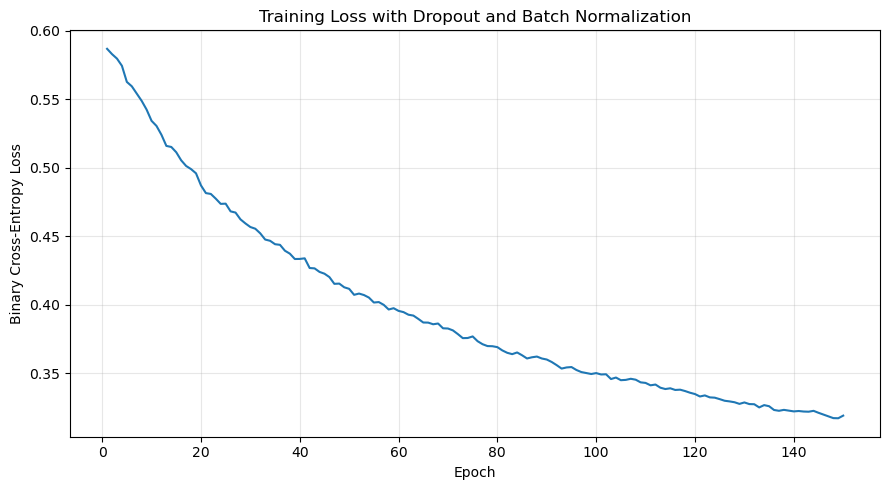

In [24]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(losses) + 1), losses)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training Loss with Dropout and Batch Normalization")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
_, cache = forward(
    X_train, model, training=False, dropout_rate=0
)

print("\nBATCH NORMALIZATION CHECK")
print("-------------------------")
print(
    "Hidden layer 1 normalized activation mean:",
    round(float(np.mean(cache["bn1"])), 4)
)
print(
    "Hidden layer 1 normalized activation variance:",
    round(float(np.var(cache["bn1"])), 4)
)
print(
    "Hidden layer 2 normalized activation mean:",
    round(float(np.mean(cache["bn2"])), 4)
)
print(
    "Hidden layer 2 normalized activation variance:",
    round(float(np.var(cache["bn2"])), 4)
)



BATCH NORMALIZATION CHECK
-------------------------
Hidden layer 1 normalized activation mean: 0.0002
Hidden layer 1 normalized activation variance: 1.0352
Hidden layer 2 normalized activation mean: 0.012
Hidden layer 2 normalized activation variance: 0.76
